In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [3]:
# Load Fashion MNIST dataset
(x_train, y_train), (x_test, y_test) = datasets.fashion_mnist.load_data()

# Normalize pixel values to range 0-1
x_train = x_train / 255.0
x_test = x_test / 255.0

# Add channel dimension for grayscale images (28, 28) -> (28, 28, 1)
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)

# Define fashion class names
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Print data dimensions
print("Training data shape:", x_train.shape)
print("Test data shape:", x_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28, 1)
Test data shape: (10000, 28, 28, 1)


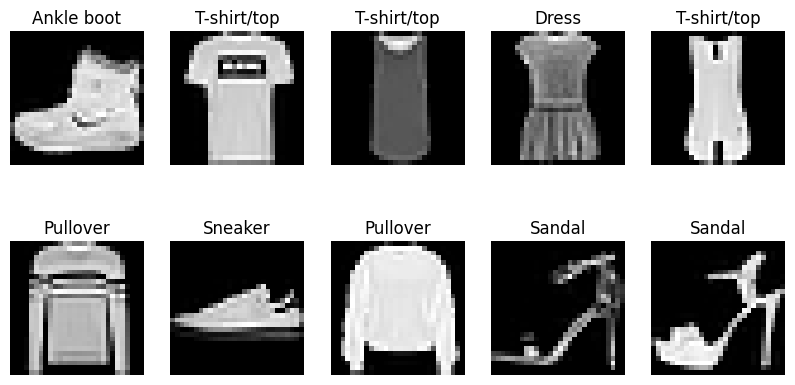

In [5]:
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    # Using cmap='gray' since Fashion MNIST is grayscale
    plt.imshow(x_train[i].squeeze(), cmap='gray')
    # Fashion MNIST targets are 1D, index directly as y_train[i]
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.show()

In [4]:
model = models.Sequential([
    # First Convolutional Block (adjusted input_shape for Fashion MNIST 28x28x1)
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),

    # Second Convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Third Convolutional Block
    layers.Conv2D(128, (3, 3), activation='relu'),

    # Classification / Fully Connected Layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:
# Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train model
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 53s 68ms/step - accuracy: 0.7623 - loss: 0.6479 - val_accuracy: 0.8505 - val_loss: 0.3943
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 81s 67ms/step - accuracy: 0.8597 - loss: 0.3943 - val_accuracy: 0.8820 - val_loss: 0.3272
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 80s 65ms/step - accuracy: 0.8771 - loss: 0.3390 - val_accuracy: 0.8914 - val_loss: 0.2936
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 50s 66ms/step - accuracy: 0.8940 - loss: 0.2995 - val_accuracy: 0.8968 - val_loss: 0.2775
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 82s 66ms/step - accuracy: 0.9009 - loss: 0.2730 - val_accuracy: 0.9000 - val_loss: 0.2725
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 49s 66ms/step - accuracy: 0.9084 - loss: 0.2549 - val_accuracy: 0.9028 - val_loss: 0.2606
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 48s 64ms/step - accuracy: 0.9159 - loss: 0.2314 - val_accuracy: 0.9072 - val_loss: 0.2570
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 50s 66ms/step - accuracy: 0.9217 - loss: 0.2159 - 

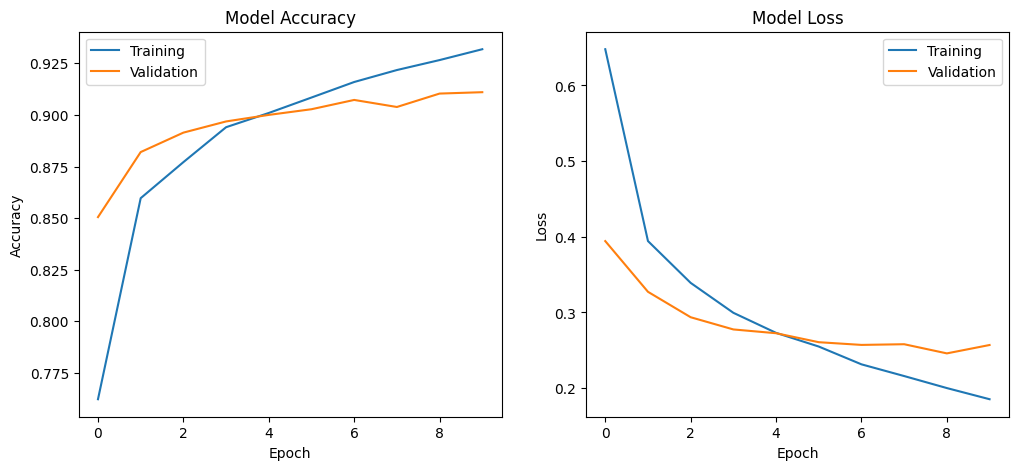

In [8]:
plt.figure(figsize=(12, 5))

# Accuracy Plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss Plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

313/313 - 5s - 15ms/step - accuracy: 0.9079 - loss: 0.2737
Test Accuracy: 0.9078999757766724
Test Loss: 0.27370020747184753
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step


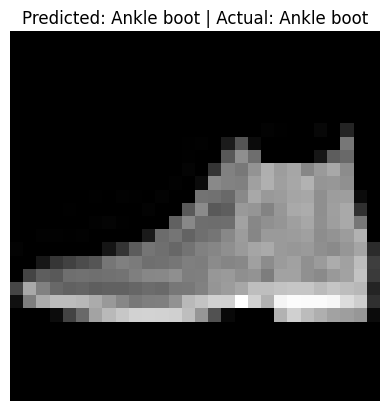

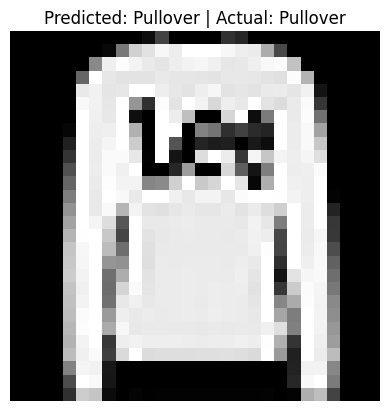

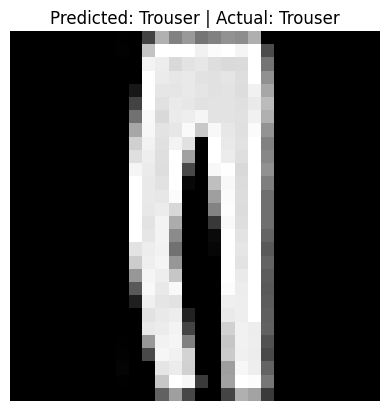

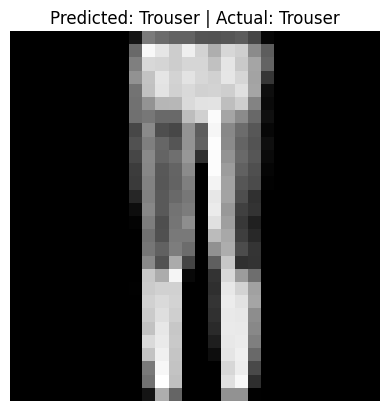

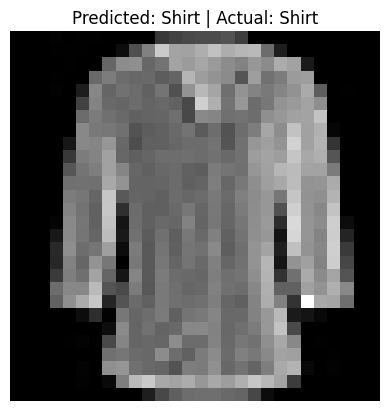

In [9]:
# Evaluate test loss and accuracy
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print("Test Accuracy:", test_acc)
print("Test Loss:", test_loss)

# Generate predictions
predictions = model.predict(x_test)

# Display predictions for first 5 test samples
for i in range(5):
    predicted_label = np.argmax(predictions[i])
    # Fashion MNIST target array is 1D
    actual_label = y_test[i]

    plt.figure()
    plt.imshow(x_test[i].squeeze(), cmap='gray')
    plt.title(f"Predicted: {class_names[predicted_label]} | Actual: {class_names[actual_label]}")
    plt.axis('off')
    plt.show()

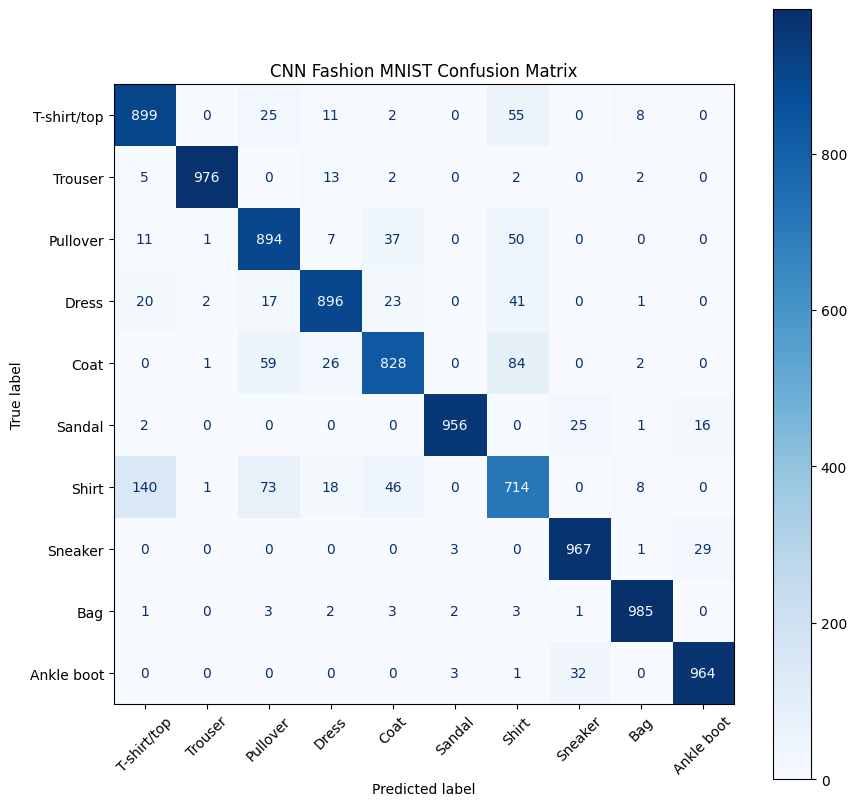

In [12]:
# Extract predicted and true class labels
y_pred = np.argmax(predictions, axis=1)
y_true = y_test.flatten()

# Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Display confusion matrix heatmap
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45, ax=ax)
plt.title('CNN Fashion MNIST Confusion Matrix')
plt.show()